# Leaf Classification: 5 classes + unknown
Self-contained notebook. Run cell by cell. Put this notebook in the same folder as `Selected Dataset leave`.

In [1]:
import pathlib, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")

# Folder that CONTAINS the class folders (one sub-folder per class, incl. "unknown").
# Finds "Selected Dataset leave" next to this notebook (works even with a double space in the name).
# Or set it yourself, e.g. DATA_DIR = pathlib.Path("Selected  Dataset leave")
DATA_DIR = next(p for p in pathlib.Path(".").iterdir() if p.is_dir() and p.name.lower().startswith("selected"))
print("Using:", DATA_DIR)
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEED = 42

def report(y_true, y_pred, class_names, title="Model"):
    print(f"=== {title} ===")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.3f}")
    print(f"Macro-F1 : {f1_score(y_true, y_pred, average='macro'):.3f}\n")
    labels = list(range(len(class_names)))
    print(classification_report(y_true, y_pred, labels=labels,
                                target_names=class_names, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"{title}: confusion matrix")
    plt.tight_layout(); plt.show()
    off = cm.copy(); np.fill_diagonal(off, 0)
    print("Most confused (true -> predicted):")
    for k in np.argsort(-off, axis=None)[:3]:
        i, j = np.unravel_index(k, off.shape)
        if off[i, j] > 0:
            print(f"  {class_names[i]} -> {class_names[j]}: {off[i, j]}")

def apply_unknown_threshold(probs, class_names, t=0.6):
    pred = probs.argmax(1)
    return np.where(probs.max(1) < t, class_names.index("unknown"), pred)

Using: Selected  Dataset leave


## 1. Check the folder structure
Each line should be one class. You should see your 5 class folders plus `unknown`.

In [2]:
for p in sorted(DATA_DIR.iterdir()):
    if p.is_dir():
        n = sum(1 for f in p.rglob("*") if f.suffix.lower() in EXTS)
        print(f"{p.name:35s} {n:5d} images")

coccinia grandis selected              54 images
Codiaeum variegatum selected           51 images
Herbarium zip                          50 images
Lembu                                  60 images
Mango selected                         62 images
unknown                                50 images


## 2. Build metadata.csv and the train/val/test split
Folder names are cleaned (`Mango selected` becomes `mango`). Edit `RENAME` to choose your own class names.

In [3]:
RENAME = {"herbarium_zip": "herbarium"}   # tidy names; add more like {"lembu": "neem"}

def clean(name):
    n = name.lower().replace("selected", "").strip().replace(" ", "_")
    return RENAME.get(n, n)

rows = []
for cls_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for f in sorted(cls_dir.rglob("*")):
        if f.suffix.lower() not in EXTS:
            continue
        try:
            with Image.open(f) as im:
                w, h = im.size
        except Exception as e:
            print("Skipping", f.name, e); continue
        rows.append(dict(filepath=str(f), filename=f.name, cls=clean(cls_dir.name), width=w, height=h))
df = pd.DataFrame(rows).rename(columns={"cls": "class"})
df = df.groupby("class").filter(lambda g: len(g) >= 3)    # drop empty/near-empty folders
class_names = sorted(df["class"].unique())
assert "unknown" in class_names, "No 'unknown' folder found"

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["class"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["class"], random_state=SEED)
df.loc[train_df.index, "split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"
df.to_csv("metadata.csv", index=False)
print(class_names)
df.groupby(["class", "split"]).size().unstack(fill_value=0)

['coccinia_grandis', 'codiaeum_variegatum', 'herbarium', 'lembu', 'mango', 'unknown']


split,test,train,val
class,,,
coccinia_grandis,8,38,8
codiaeum_variegatum,8,35,8
herbarium,7,35,8
lembu,9,42,9
mango,10,43,9
unknown,8,35,7


## 3. EDA

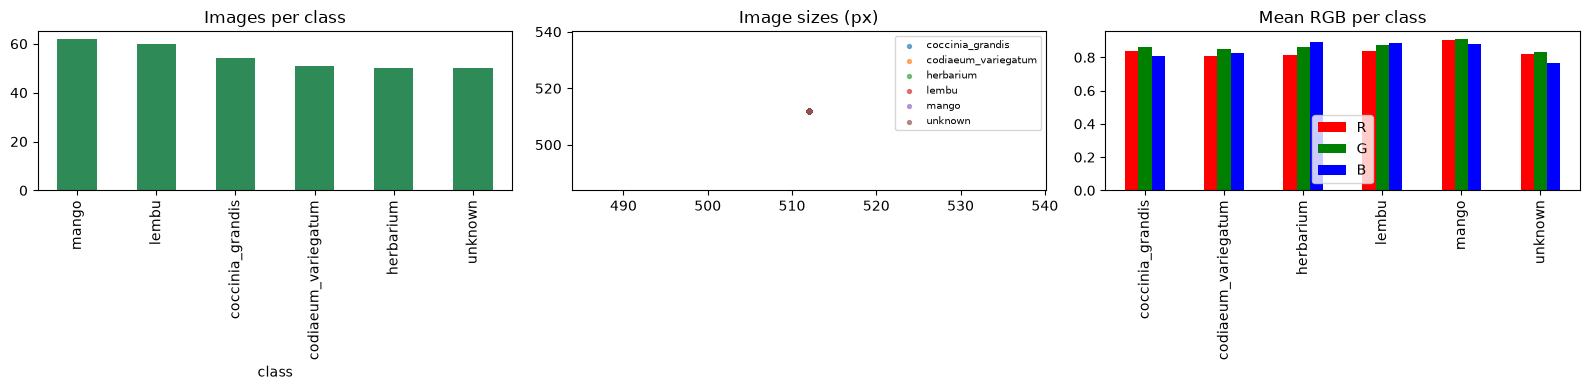

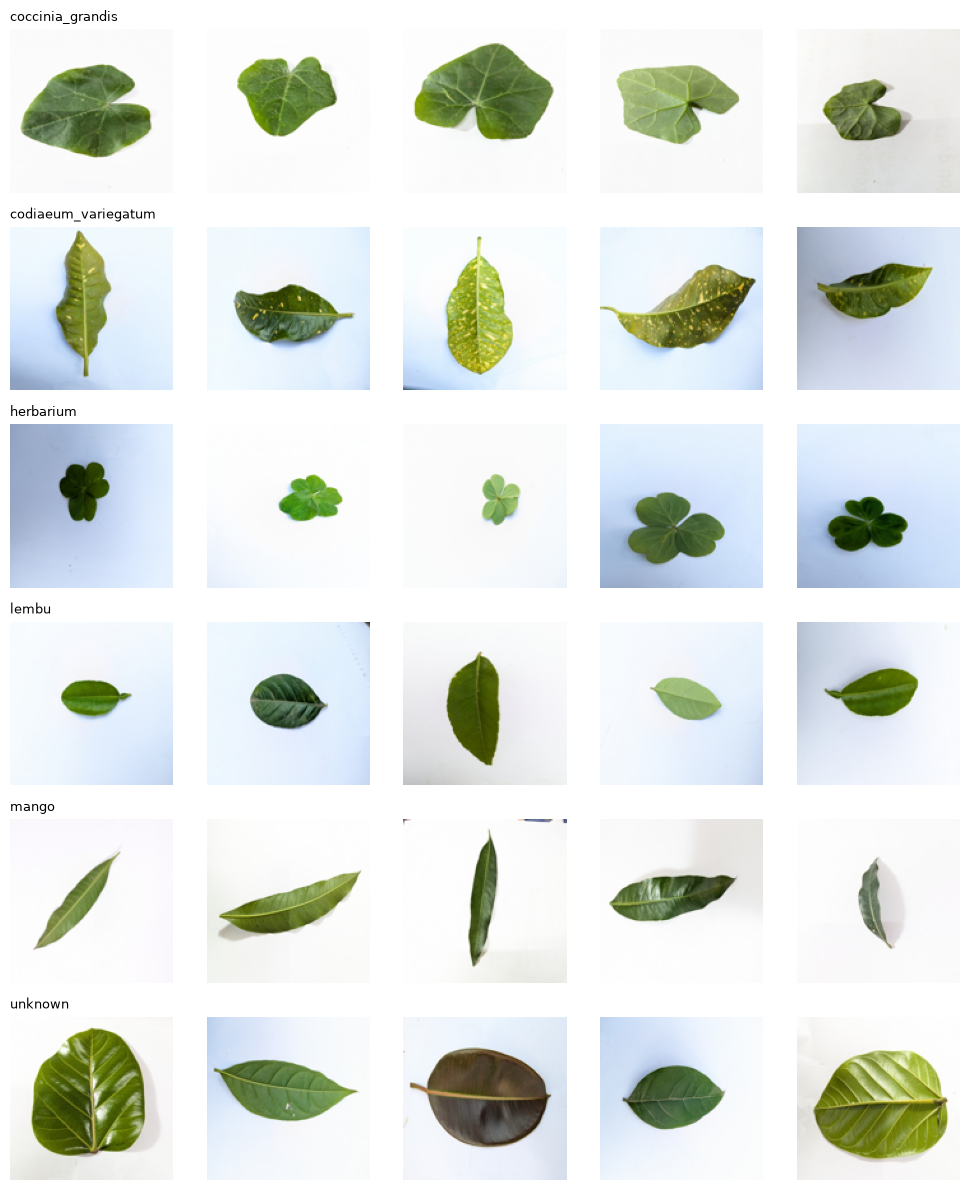

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["class"].value_counts().plot(kind="bar", ax=ax[0], color="seagreen"); ax[0].set_title("Images per class")
for c, g in df.groupby("class"):
    ax[1].scatter(g.width, g.height, s=8, alpha=.6, label=c)
ax[1].set_title("Image sizes (px)"); ax[1].legend(fontsize=7)
means = {}
for c, g in df.groupby("class"):
    s = g.sample(min(30, len(g)), random_state=SEED)
    means[c] = np.stack([np.asarray(Image.open(p).convert("RGB").resize((64, 64)), dtype=float) / 255
                         for p in s.filepath]).mean(axis=(0, 1, 2))
pd.DataFrame(means, index=["R", "G", "B"]).T.plot(kind="bar", ax=ax[2], color=["r", "g", "b"])
ax[2].set_title("Mean RGB per class")
plt.tight_layout(); plt.show()

n = 5
fig, axes = plt.subplots(len(class_names), n, figsize=(2 * n, 2 * len(class_names)))
for i, c in enumerate(class_names):
    s = df[df["class"] == c].sample(min(n, (df["class"] == c).sum()), random_state=SEED)
    for j in range(n):
        axes[i, j].axis("off")
        if j < len(s):
            axes[i, j].imshow(Image.open(s.iloc[j].filepath).convert("RGB").resize((128, 128)))
        if j == 0:
            axes[i, j].set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 4. Baseline: colour + texture + shape features, Random Forest / SVM

In [5]:
from skimage.feature import local_binary_pattern
from skimage.filters import threshold_otsu
from skimage.measure import label as sk_label, regionprops
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def features(path, size=128):
    img = Image.open(path).convert("RGB").resize((size, size))
    hsv = np.asarray(img.convert("HSV"))
    color = np.concatenate([np.histogram(hsv[..., c], bins=16, range=(0, 256))[0] for c in range(3)]).astype(float)
    color /= color.sum()
    gray = np.asarray(img.convert("L"))
    lbp = local_binary_pattern(gray, 8, 1, "uniform")
    texture = np.histogram(lbp, bins=10, range=(0, 10), density=True)[0]
    mask = gray > threshold_otsu(gray)
    if mask.mean() > 0.5:          # keep the smaller region = leaf
        mask = ~mask
    props = regionprops(sk_label(mask))
    if props:
        r = max(props, key=lambda p: p.area)
        h = r.bbox[2] - r.bbox[0]; w = r.bbox[3] - r.bbox[1]
        shape = [r.area / size**2, w / (h + 1e-9), r.solidity, r.eccentricity, r.extent]
    else:
        shape = [0] * 5
    return np.concatenate([color, texture, shape])

idx = {c: i for i, c in enumerate(class_names)}
def build_xy(d):
    return np.stack([features(p) for p in d.filepath]), d["class"].map(idx).values

Xtr, ytr = build_xy(df[df.split != "test"])      # train + val
Xte, yte = build_xy(df[df.split == "test"])
print(Xtr.shape, Xte.shape)

(277, 63) (50, 63)


=== Baseline Random Forest ===
Accuracy : 0.960
Macro-F1 : 0.961

                     precision    recall  f1-score   support

   coccinia_grandis       1.00      1.00      1.00         8
codiaeum_variegatum       1.00      0.88      0.93         8
          herbarium       1.00      1.00      1.00         7
              lembu       0.82      1.00      0.90         9
              mango       1.00      1.00      1.00        10
            unknown       1.00      0.88      0.93         8

           accuracy                           0.96        50
          macro avg       0.97      0.96      0.96        50
       weighted avg       0.97      0.96      0.96        50



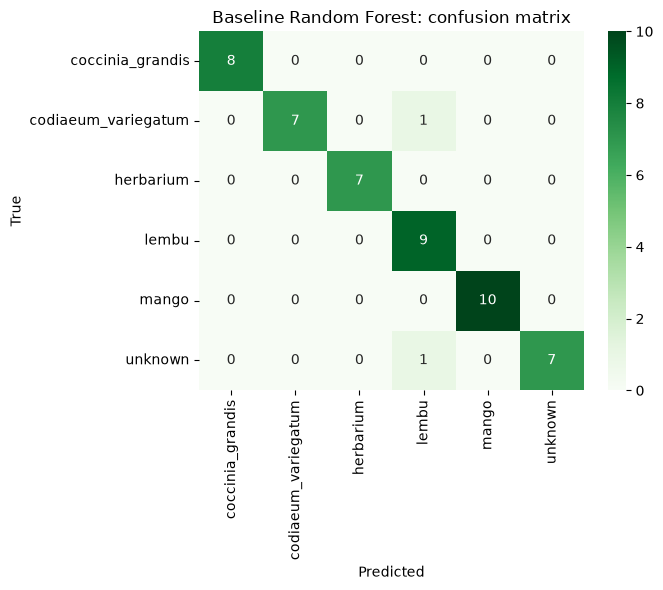

Most confused (true -> predicted):
  codiaeum_variegatum -> lembu: 1
  unknown -> lembu: 1
=== Baseline SVM ===
Accuracy : 0.900
Macro-F1 : 0.898

                     precision    recall  f1-score   support

   coccinia_grandis       0.80      1.00      0.89         8
codiaeum_variegatum       1.00      0.75      0.86         8
          herbarium       1.00      1.00      1.00         7
              lembu       0.89      0.89      0.89         9
              mango       0.91      1.00      0.95        10
            unknown       0.86      0.75      0.80         8

           accuracy                           0.90        50
          macro avg       0.91      0.90      0.90        50
       weighted avg       0.91      0.90      0.90        50



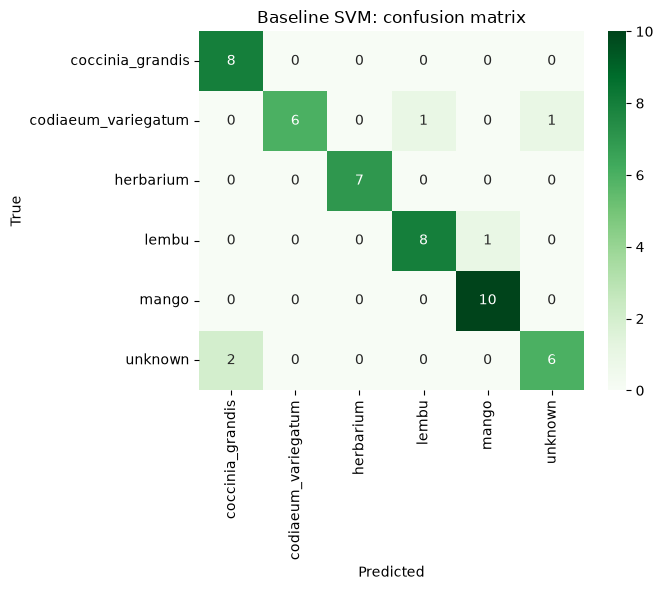

Most confused (true -> predicted):
  unknown -> coccinia_grandis: 2
  codiaeum_variegatum -> unknown: 1
  lembu -> mango: 1


In [6]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "SVM": make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=SEED)),
}
for name, m in models.items():
    m.fit(Xtr, ytr)
    report(yte, m.predict(Xte), class_names, f"Baseline {name}")

## 5. Transfer learning: MobileNetV2

In [7]:
# [TF]
import tensorflow as tf
from tensorflow.keras import layers, models as kmodels
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG, BATCH = 224, 32
tf.keras.utils.set_random_seed(SEED)

def make_ds(d, training=False):
    paths = d.filepath.values
    labels = d["class"].map(idx).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    def load(p, y):
        im = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        return tf.image.resize(im, (IMG, IMG)), y
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(df[df.split == "train"], True)
val_ds = make_ds(df[df.split == "val"])
test_d = df[df.split == "test"]
test_ds = make_ds(test_d)

augment = tf.keras.Sequential([layers.RandomFlip("horizontal_and_vertical"),
                               layers.RandomRotation(0.15), layers.RandomZoom(0.1),
                               layers.RandomBrightness(0.2)])
base = MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False
inp = layers.Input((IMG, IMG, 3))
x = preprocess_input(augment(inp))
x = base(x, training=False)
x = layers.Dropout(0.3)(layers.GlobalAveragePooling2D()(x))
model = kmodels.Model(inp, layers.Dense(len(class_names), activation="softmax")(x))
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=10)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step
Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.2851 - loss: 1.9102 - val_accuracy: 0.5510 - val_loss: 1.3313
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.5746 - loss: 1.1443 - val_accuracy: 0.7347 - val_loss: 0.8351
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.7675 - loss: 0.7211 - val_accuracy: 0.8367 - val_loss: 0.5547
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8640 - loss: 0.4780 - val_accuracy: 0.8980 - val_loss: 0.4800
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8816 - loss: 0.4490 - val_accuracy: 0.9184 - val_loss: 0.3841
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8772 - loss: 0.3711 - val_accuracy: 0.9388 - val_loss: 0.3221
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.9123 - loss: 0.3099 - val_accuracy: 0.9388 - val_loss: 0.2778
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.9167 - loss: 0.2493 -

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.5175 - loss: 1.3610 - val_accuracy: 0.9388 - val_loss: 0.2327
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.6316 - loss: 1.0298 - val_accuracy: 0.9388 - val_loss: 0.2211
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.6140 - loss: 1.0342 - val_accuracy: 0.9388 - val_loss: 0.2139
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.7412 - loss: 0.8426 - val_accuracy: 0.9388 - val_loss: 0.2084
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.7281 - loss: 0.7199 - val_accuracy: 0.9592 - val_loss: 0.2080


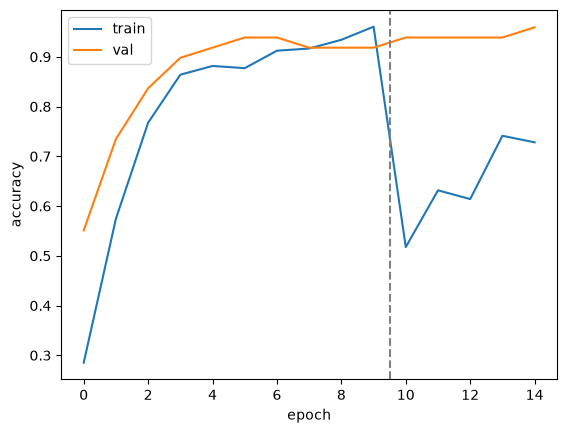

In [8]:
# [TF] Fine-tune the top 30 layers of MobileNetV2 with a low learning rate
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=5)

acc = h1.history["accuracy"] + h2.history["accuracy"]
val = h1.history["val_accuracy"] + h2.history["val_accuracy"]
plt.plot(acc, label="train"); plt.plot(val, label="val")
plt.axvline(len(h1.history["accuracy"]) - 0.5, ls="--", c="gray")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.show()
model.save("leaf_mobilenetv2.keras")
json.dump(class_names, open("class_names.json", "w"))

## 6. Test-set evaluation and the 'unknown' threshold

2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 3s/step
=== MobileNetV2 ===
Accuracy : 0.880
Macro-F1 : 0.865

                     precision    recall  f1-score   support

   coccinia_grandis       1.00      0.88      0.93         8
codiaeum_variegatum       0.89      1.00      0.94         8
          herbarium       1.00      1.00      1.00         7
              lembu       0.69      1.00      0.82         9
              mango       1.00      1.00      1.00        10
            unknown       0.75      0.38      0.50         8

           accuracy                           0.88        50
          macro avg       0.89      0.88      0.87        50
       weighted avg       0.89      0.88      0.87        50



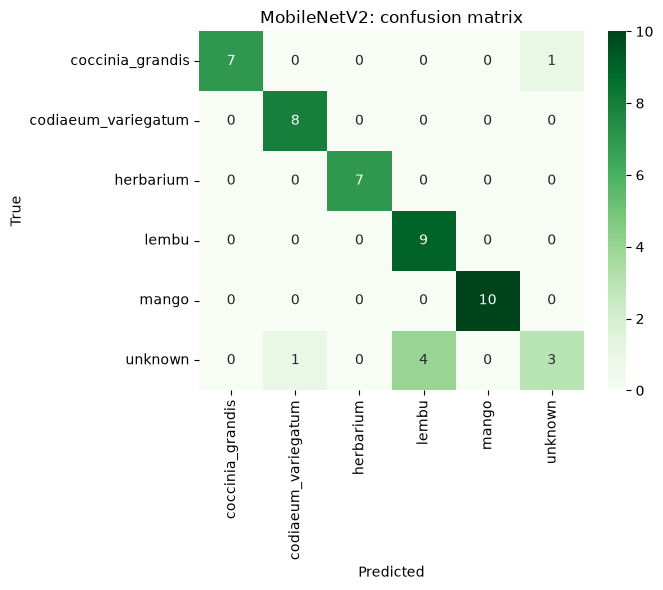

Most confused (true -> predicted):
  unknown -> lembu: 4
  coccinia_grandis -> unknown: 1
  unknown -> codiaeum_variegatum: 1


In [9]:
# [TF]
y_true = test_d["class"].map(idx).values
probs = model.predict(test_ds)
report(y_true, probs.argmax(1), class_names, "MobileNetV2")

threshold 0.4: accuracy 0.880  macro-F1 0.865
threshold 0.5: accuracy 0.880  macro-F1 0.865
threshold 0.6: accuracy 0.960  macro-F1 0.959
threshold 0.7: accuracy 0.960  macro-F1 0.962
threshold 0.8: accuracy 0.900  macro-F1 0.910
=== MobileNetV2 + threshold 0.6 ===
Accuracy : 0.960
Macro-F1 : 0.959

                     precision    recall  f1-score   support

   coccinia_grandis       1.00      0.88      0.93         8
codiaeum_variegatum       1.00      1.00      1.00         8
          herbarium       1.00      1.00      1.00         7
              lembu       0.90      1.00      0.95         9
              mango       1.00      1.00      1.00        10
            unknown       0.88      0.88      0.88         8

           accuracy                           0.96        50
          macro avg       0.96      0.96      0.96        50
       weighted avg       0.96      0.96      0.96        50



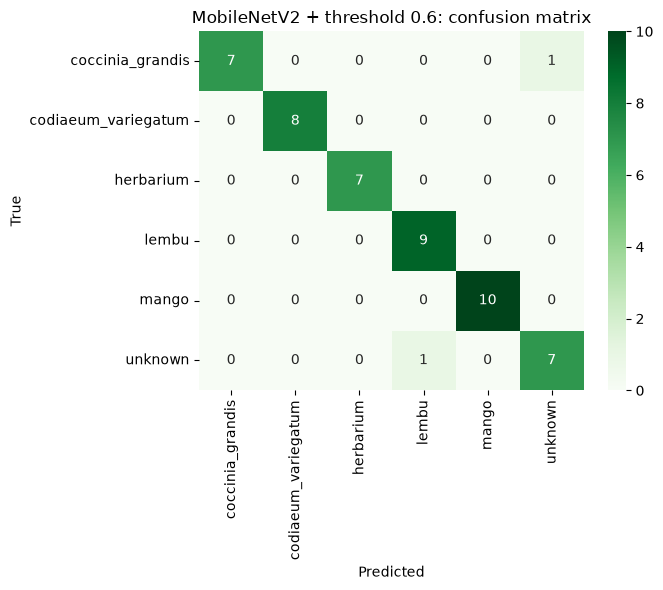

Most confused (true -> predicted):
  coccinia_grandis -> unknown: 1
  unknown -> lembu: 1


In [10]:
# [TF] Low-confidence predictions are relabelled "unknown"
for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    p = apply_unknown_threshold(probs, class_names, t)
    print(f"threshold {t}: accuracy {accuracy_score(y_true, p):.3f}  macro-F1 {f1_score(y_true, p, average='macro'):.3f}")
report(y_true, apply_unknown_threshold(probs, class_names, 0.6), class_names, "MobileNetV2 + threshold 0.6")

## 7. Discussion
Which classes were confused, and why? (similar shape, lighting, background, too few photos...)

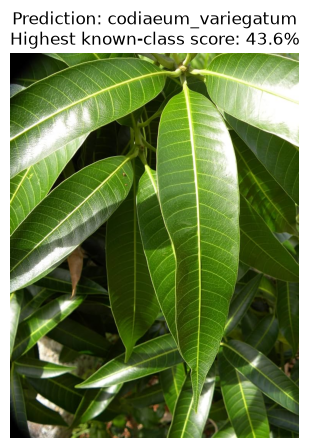

File: C:/Users/HP/Downloads/71npmi8ag1L._AC_UF894,1000_QL80_.jpg
🌿 Predicted result: codiaeum_variegatum
Highest known-class score: 43.63%

Scores for each class:
coccinia_grandis: 0.70%
codiaeum_variegatum: 43.63%
herbarium: 1.35%
lembu: 0.79%
mango: 38.72%
unknown: 14.80%


In [22]:

# ============================================================
# EXTERNAL LEAF IDENTIFICATION + UNKNOWN LEAF DETECTION
# ============================================================

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tkinter as tk
from tkinter import filedialog

# Adjust this threshold after testing on known and unknown images.
CONFIDENCE_THRESHOLD = 0.35

def identify_external_leaf():
    # Open a file picker so you can select any image from your PC
    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    image_path = filedialog.askopenfilename(
        title="Select an external leaf image",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp *.webp"),
            ("All files", "*.*")
        ]
    )

    root.destroy()

    if not image_path:
        print("No image selected.")
        return

    try:
        # Load and resize image
        original_image = Image.open(image_path).convert("RGB")
        resized_image = original_image.resize((IMG, IMG))

        image_array = np.asarray(resized_image, dtype=np.float32)
        image_batch = np.expand_dims(image_array, axis=0)

        # Predict with the trained MobileNetV2 model
        probabilities = model.predict(image_batch, verbose=0)[0]

        # Separate known species from the unknown class
        known_indices = [
            i for i, name in enumerate(class_names)
            if name.lower() != "unknown"
        ]

        unknown_indices = [
            i for i, name in enumerate(class_names)
            if name.lower() == "unknown"
        ]

        if not known_indices:
            print("Error: No known species classes found.")
            return

        best_known_index = max(
            known_indices,
            key=lambda i: probabilities[i]
        )
        best_known_score = float(probabilities[best_known_index])

        unknown_score = (
            float(probabilities[unknown_indices[0]])
            if unknown_indices else 0.0
        )

        # Reject predictions that are uncertain or favour the unknown class
        if (
            unknown_indices
            and unknown_score >= best_known_score
        ) or best_known_score < CONFIDENCE_THRESHOLD:
            result = "Unknown leaf"
        else:
            result = class_names[best_known_index]

        # Display the selected image and prediction
        plt.figure(figsize=(7, 5))
        plt.imshow(original_image)
        plt.axis("off")
        plt.title(
            f"Prediction: {result}\n"
            f"Highest known-class score: {best_known_score:.1%}"
        )
        plt.show()

        print("File:", image_path)
        print("🌿 Predicted result:", result)
        print(f"Highest known-class score: {best_known_score:.2%}")

        print("\nScores for each class:")
        for name, score in zip(class_names, probabilities):
            print(f"{name}: {score:.2%}")

    except Exception as error:
        print("Could not process this image:", error)


# Run the image selector
identify_external_leaf()
